In [ ]:
import warnings
warnings.filterwarnings(action="ignore", message=r"datetime.datetime.utcnow")

# PERSIAPAN

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

Pada laporan praktikum, sisipkan penjelasan singkat mengenai library:
- `sklearn` (ambil dari https://scikit-learn.org/stable/)
- `statsmodels` (ambil dari https://statsmodels.org)

pada **BAB 2** di bagian metode yang melibatkannya.

In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [ ]:
import os
os.chdir('drive/MyDrive/sml') # ganti dengan folder hasil copy kalian

In [ ]:
df_all = pd.read_csv("water.csv")
df_all.head()

,Time,WaterUsage
0,2011-01-01,2.46
1,2011-01-02,2.03
2,2011-01-02,2.03
3,2011-01-03,2.50
4,2011-01-04,2.05


Kasus ini memodelkan data *time series* konsumsi air harian sebuah rumah tangga, dengan populasi berupa seluruh hari dalam rentang waktu pengamatan 1 Januari 2011 hingga 31 Desember 2020 untuk satu rumah tangga yang sama.
- `Time`: tanggal pengamatan konsumsi air
- `WaterUsage`: volume konsumsi air rumah tangga pada hari tersebut (dalam satuan meter kubik per hari)

Pemilihan variabel

In [ ]:
df_all.columns

Index(['Time', 'WaterUsage'], dtype='object')

In [ ]:
df_raw = df_all[['Time', 'WaterUsage']]
print('5 baris awal')
display(df_raw.head())
print('5 baris akhir')
display(df_raw.tail())

5 baris awal


,Time,WaterUsage
0,2011-01-01,2.46
1,2011-01-02,2.03
2,2011-01-02,2.03
3,2011-01-03,2.50
4,2011-01-04,2.05


5 baris akhir


,Time,WaterUsage
3940,2020-12-28,NaN
3941,2020-12-29,9.19
3942,2020-12-30,8.95
3943,2020-12-30,8.95
3944,2020-12-31,9.39


Mempersingkat nama kolom

In [ ]:
df_raw.columns = ['time', 'water']
df_raw.head()

,time,water
0,2011-01-01,2.46
1,2011-01-02,2.03
2,2011-01-02,2.03
3,2011-01-03,2.50
4,2011-01-04,2.05


Mengubah data pada kolom tanggal/waktu menjadi tipe datetime

In [ ]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3945 entries, 0 to 3944
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   time    3945 non-null   object 
 1   water   3751 non-null   float64
dtypes: float64(1), object(1)
memory usage: 61.8+ KB


In [ ]:
df_raw['time'] = pd.to_datetime(df_raw['time'])
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3945 entries, 0 to 3944
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   time    3945 non-null   datetime64[ns]
 1   water   3751 non-null   float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 61.8 KB


# EDA

### Statistik Nilai

In [ ]:
df_raw['water'].describe()

,water
count,3751.000000
mean,6.167987
std,2.204719
min,0.470000
25%,4.095000
50%,6.180000
75%,8.200000
max,14.650000


## Statistik Waktu

In [ ]:
def explore_time(t):
  start = t.min()
  end = t.max()

  print("Mulai   :", start)
  print("Selesai :", end)
  print("Durasi  :", end - start)
  print()

  year_count = len(pd.unique(t.dt.year))
  total_months = (end.year - start.year) * 12 + (end.month - start.month) + 1

  print(f"Jumlah Tahun : {year_count} ({start.year}-{end.year})")
  print(f"Jumlah Bulan : {total_months}")
  print()

  freq = pd.infer_freq(t)
  if freq is None:
      scale = "Tidak konsisten"
  elif freq in ['M','MS','ME','BM','BMS']:
      scale = "Bulanan"
  elif freq in ['A','AS','Y','YS']:
      scale = "Tahunan"
  elif freq in ['D','B']:
      scale = "Harian"
  else:
      scale = f"Tidak dikenal ({freq})"

  print("Skala Data :", scale)
  print("Frekuensi  :", freq)
  print()

  diff = t.diff().dropna()
  print("Jumlah Selisih Unik:", diff.nunique())
  display(diff.value_counts())
  print()

  print("Jumlah Data per Tahun:")
  display(t.dt.year.value_counts().sort_index())
  print()

  print("Jumlah Data per Bulan:")
  display(t.dt.month.value_counts().sort_index())
  print()

In [ ]:
explore_time(df_raw['time'])

Mulai   : 2011-01-01 00:00:00
Selesai : 2020-12-31 00:00:00
Durasi  : 3652 days 00:00:00

Jumlah Tahun : 10 (2011-2020)
Jumlah Bulan : 120

Skala Data : Tidak konsisten
Frekuensi  : None

Jumlah Selisih Unik: 2


,count
time,
1 days,3652
0 days,292



Jumlah Data per Tahun:


,count
time,
2011,390
2012,392
2013,393
2014,397
2015,398
2016,388
2017,392
2018,391
2019,410



Jumlah Data per Bulan:


,count
time,
1,333
2,305
3,338
4,320
5,338
6,329
7,333
8,333
9,318


## Time Series Plot

In [ ]:
def plot_time_series(x, y, xlabel, ylabel, title, figsize=(7, 4), dpi=300):
    print(title)

    plt.figure(figsize=figsize, dpi=dpi)
    plt.plot(x, y)

    ax = plt.gca()
    ax.set_axisbelow(True)
    ax.grid(True, axis="y", linestyle="-", alpha=0.5)

    plt.xlabel(xlabel)
    plt.ylabel(ylabel)

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    plt.tight_layout()
    plt.show()

Dinamika Volume Konsumsi Air Harian (2011-2020)


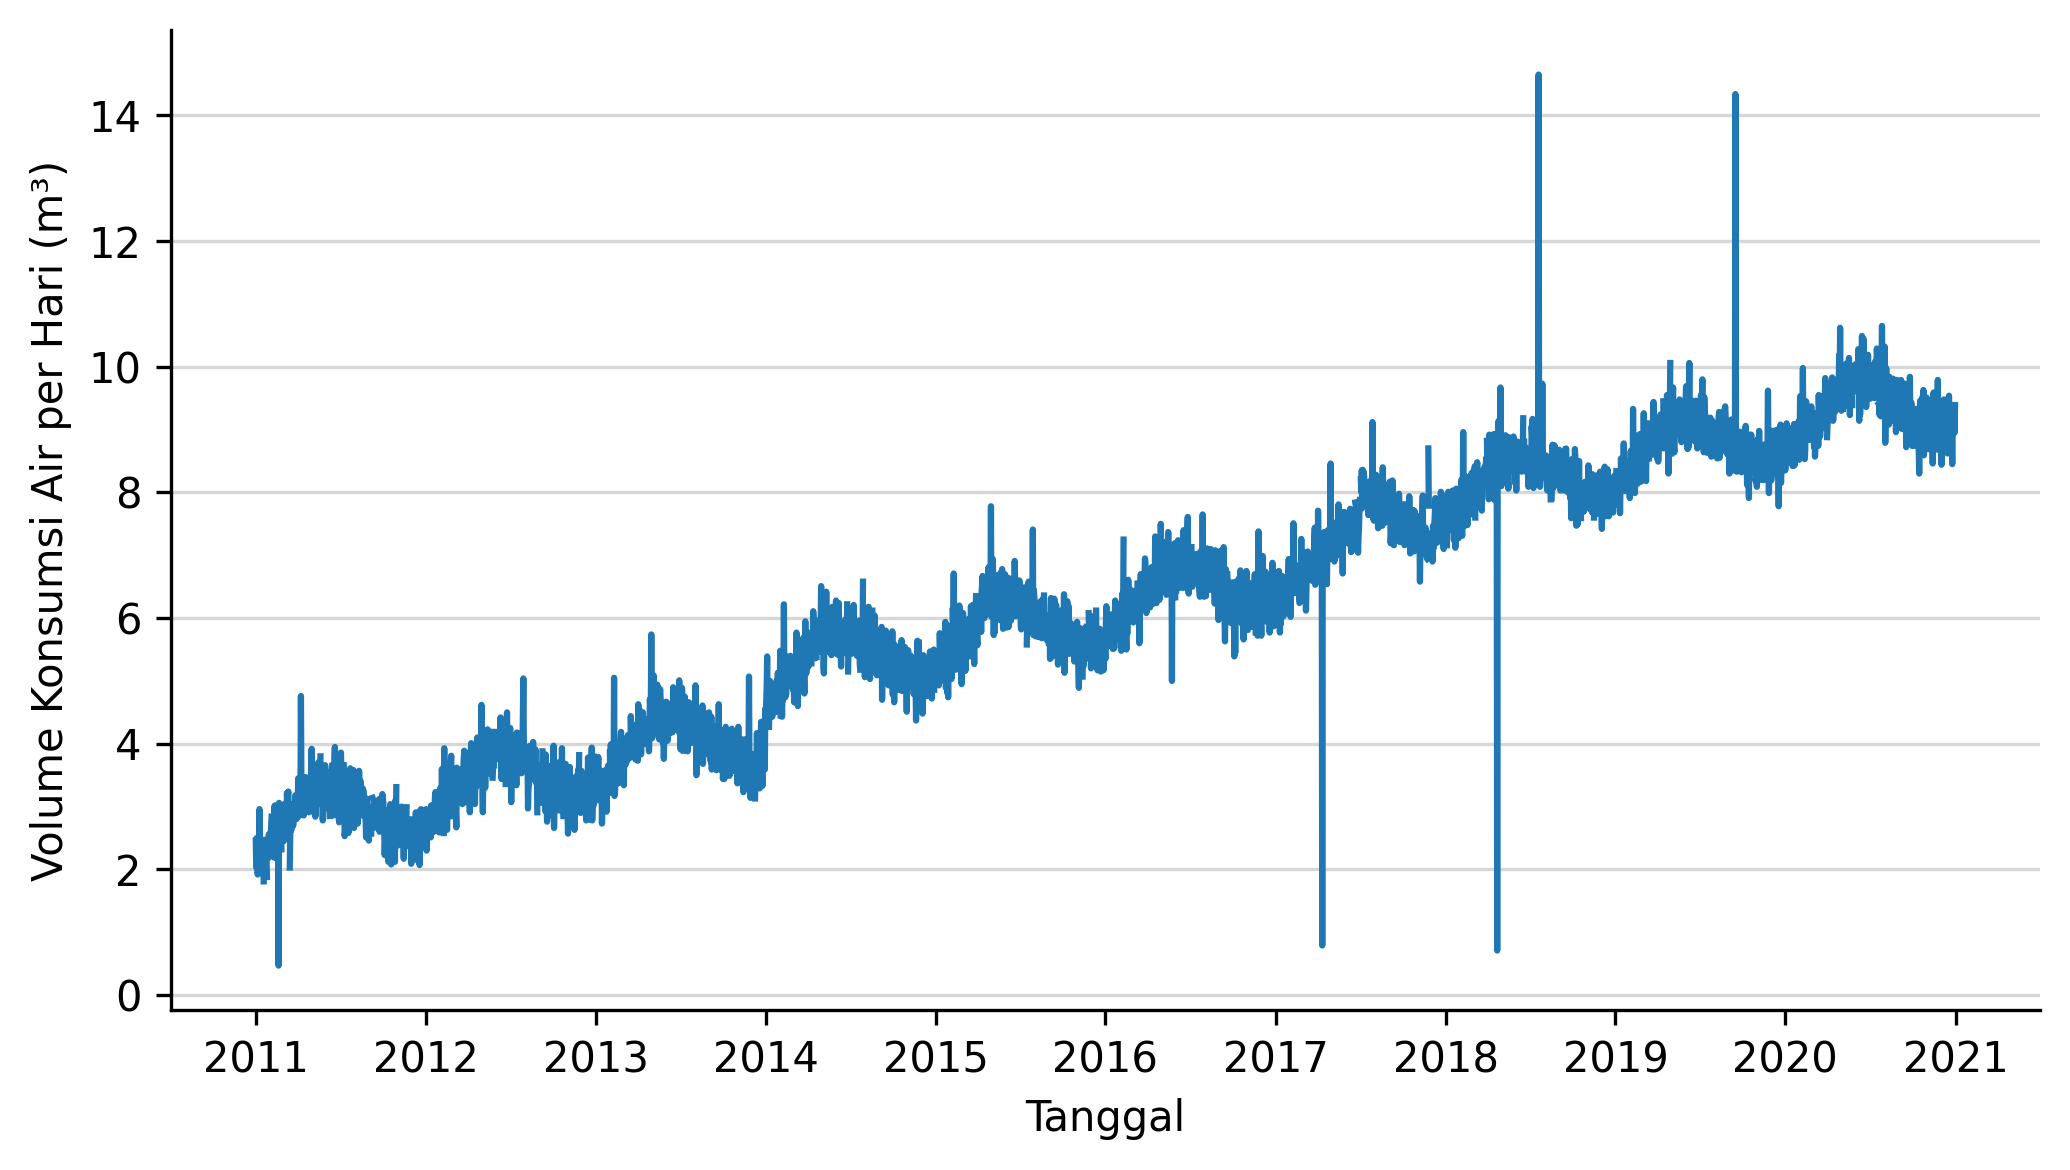

In [ ]:
plot_time_series(
    df_raw["time"],
    df_raw["water"],
    xlabel="Tanggal",
    ylabel="Volume Konsumsi Air per Hari (m³)",
    title="Dinamika Volume Konsumsi Air Harian (2011-2020)",
)

# PREPROCESSING

## Preprocessing Awal

### Data Duplikat

In [ ]:
print(df_raw.duplicated().sum(), 'baris terduplikat')
display(df_raw[df_raw.duplicated()].head())

292 baris terduplikat


,time,water
2,2011-01-02,2.03
8,2011-01-07,2.18
13,2011-01-11,2.14
45,2011-02-11,2.69
62,2011-02-27,2.53


Hapus data yang terduplikat

In [ ]:
def handle_duplicates(df, col, method="mean"):
    # method: "mean", "max", "min", "first", "last"
    return df.groupby("time", as_index=False).agg({col: method})

In [ ]:
df_no_dup = df_raw.copy()
df_no_dup = handle_duplicates(df_no_dup, 'water', method="last")
print(df_no_dup.duplicated().sum(), 'baris terduplikat')
print(f'Tersisa {len(df_no_dup)} sampel unik')

0 baris terduplikat
Tersisa 3653 sampel unik


### Outlier

In [ ]:
def cek_outlier(df, figsize=(4, 1), dpi=150):
    kolom = df.select_dtypes(include=[np.number]).columns
    if len(kolom) == 0:
        print("Tidak ada kolom numerik.")
        return

    df_checked = df[kolom]
    df_checked.plot(
        kind="box",
        subplots=True,
        layout=(len(kolom), 1),
        figsize=(figsize[0], len(kolom) * figsize[1]),
        sharex=False,
        vert=False,
    )

    fig = plt.gcf()
    fig.set_dpi(dpi)
    fig.subplots_adjust(hspace=0.6)

    plt.show()

Boxplot Sebelum Pembersihan Outlier


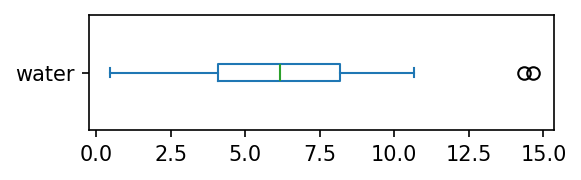

In [ ]:
print("Boxplot Sebelum Pembersihan Outlier")
cek_outlier(df_no_dup) # before

In [ ]:
df_no_outlier = df_no_dup.copy()

Hapus outlier (hanya gunakan jika diperlukan)

In [ ]:
def handle_outlier(df, kolom=None, max_iter=100):
    df_clean = df.copy()

    # kalau kolom tidak ditentukan, pakai semua kolom numerik
    if kolom is None:
        kolom = df_clean.select_dtypes(include=[np.number]).columns

    for i in range(max_iter):
        total_changed = 0

        for c in kolom:
            Q1, Q3 = df_clean[c].quantile([0.25, 0.75])
            IQR = Q3 - Q1
            lower = Q1 - 1.5 * IQR
            upper = Q3 + 1.5 * IQR

            # hanya yang masih bukan NaN yang dicek
            mask_out = df_clean[c].notna() & ~df_clean[c].between(lower, upper)
            n_out = mask_out.sum()

            if n_out > 0:
                df_clean.loc[mask_out, c] = np.nan
                total_changed += n_out

        if total_changed == 0:
            print(f"Tidak ada outlier baru pada iterasi ke-{i+1}, berhenti.")
            break

        print(f"Iterasi {i+1}: {total_changed} outlier diubah menjadi missing value.")

    return df_clean

Uncomment cell berikut jika dirasa perlu untuk menangani outlier:

Iterasi 1: 2 outlier diubah menjadi missing value.
Tidak ada outlier baru pada iterasi ke-2, berhenti.

Boxplot Setelah Pembersihan Outlier


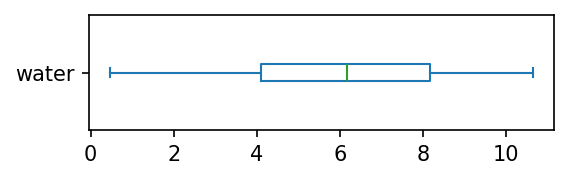

In [ ]:
# df_no_outlier = handle_outlier(df_no_dup.copy())
# print("\nBoxplot Setelah Pembersihan Outlier")
# cek_outlier(df_no_outlier)

### Missing Value

Cek sebelum lengkap

In [ ]:
print('Total Missing Value')
print(df_no_outlier.isnull().sum())

Total Missing Value
time       0
water    184
dtype: int64


In [ ]:
df = df_no_outlier.copy()

**Beberapa opsi penanganan missing value pada data time series adalah sebagai berikut:**

- Mengimputasi dengan interpolasi berdasarkan skala waktu

In [ ]:
col = 'water' # kolom yang mengandung missing value
df[col] = (
    df
      .set_index('time')[col]
      .interpolate(method='time', limit_direction='both')
      .to_numpy()
)

- Mengimputasi dengan nilai periode sebelumnya (forward fill)

In [ ]:
# col = 'water' # kolom yang mengandung missing value
# df[col] = df[col].ffill()

- Mengimputasi dengan nilai rata-rata atau statistik lainnya

In [ ]:
# col = 'water' # kolom yang mengandung missing value
# df[col] = df[col].fillna(df[col].mean())

- Menghapus baris (tidak disarankan jika banyak baris yang kosong)

In [ ]:
# df = df.dropna(axis=0)

Cek sesudah lengkap

In [ ]:
print('Total Missing Value')
print(df.isnull().sum())

Total Missing Value
time     0
water    0
dtype: int64


# EDA Lanjutan

## Statistik Nilai

In [ ]:
df['water'].describe()

,water
count,3653.000000
mean,6.142436
std,2.194973
min,0.470000
25%,4.080000
50%,6.160000
75%,8.170000
max,10.650000


## Statistik Waktu

In [ ]:
explore_time(df['time'])

Mulai   : 2011-01-01 00:00:00
Selesai : 2020-12-31 00:00:00
Durasi  : 3652 days 00:00:00

Jumlah Tahun : 10 (2011-2020)
Jumlah Bulan : 120

Skala Data : Harian
Frekuensi  : D

Jumlah Selisih Unik: 1


,count
time,
1 days,3652



Jumlah Data per Tahun:


,count
time,
2011,365
2012,366
2013,365
2014,365
2015,365
2016,366
2017,365
2018,365
2019,365



Jumlah Data per Bulan:


,count
time,
1,310
2,283
3,310
4,300
5,310
6,300
7,310
8,310
9,300


## Time Series Plot

Dinamika Volume Konsumsi Air Harian (2011-2020)


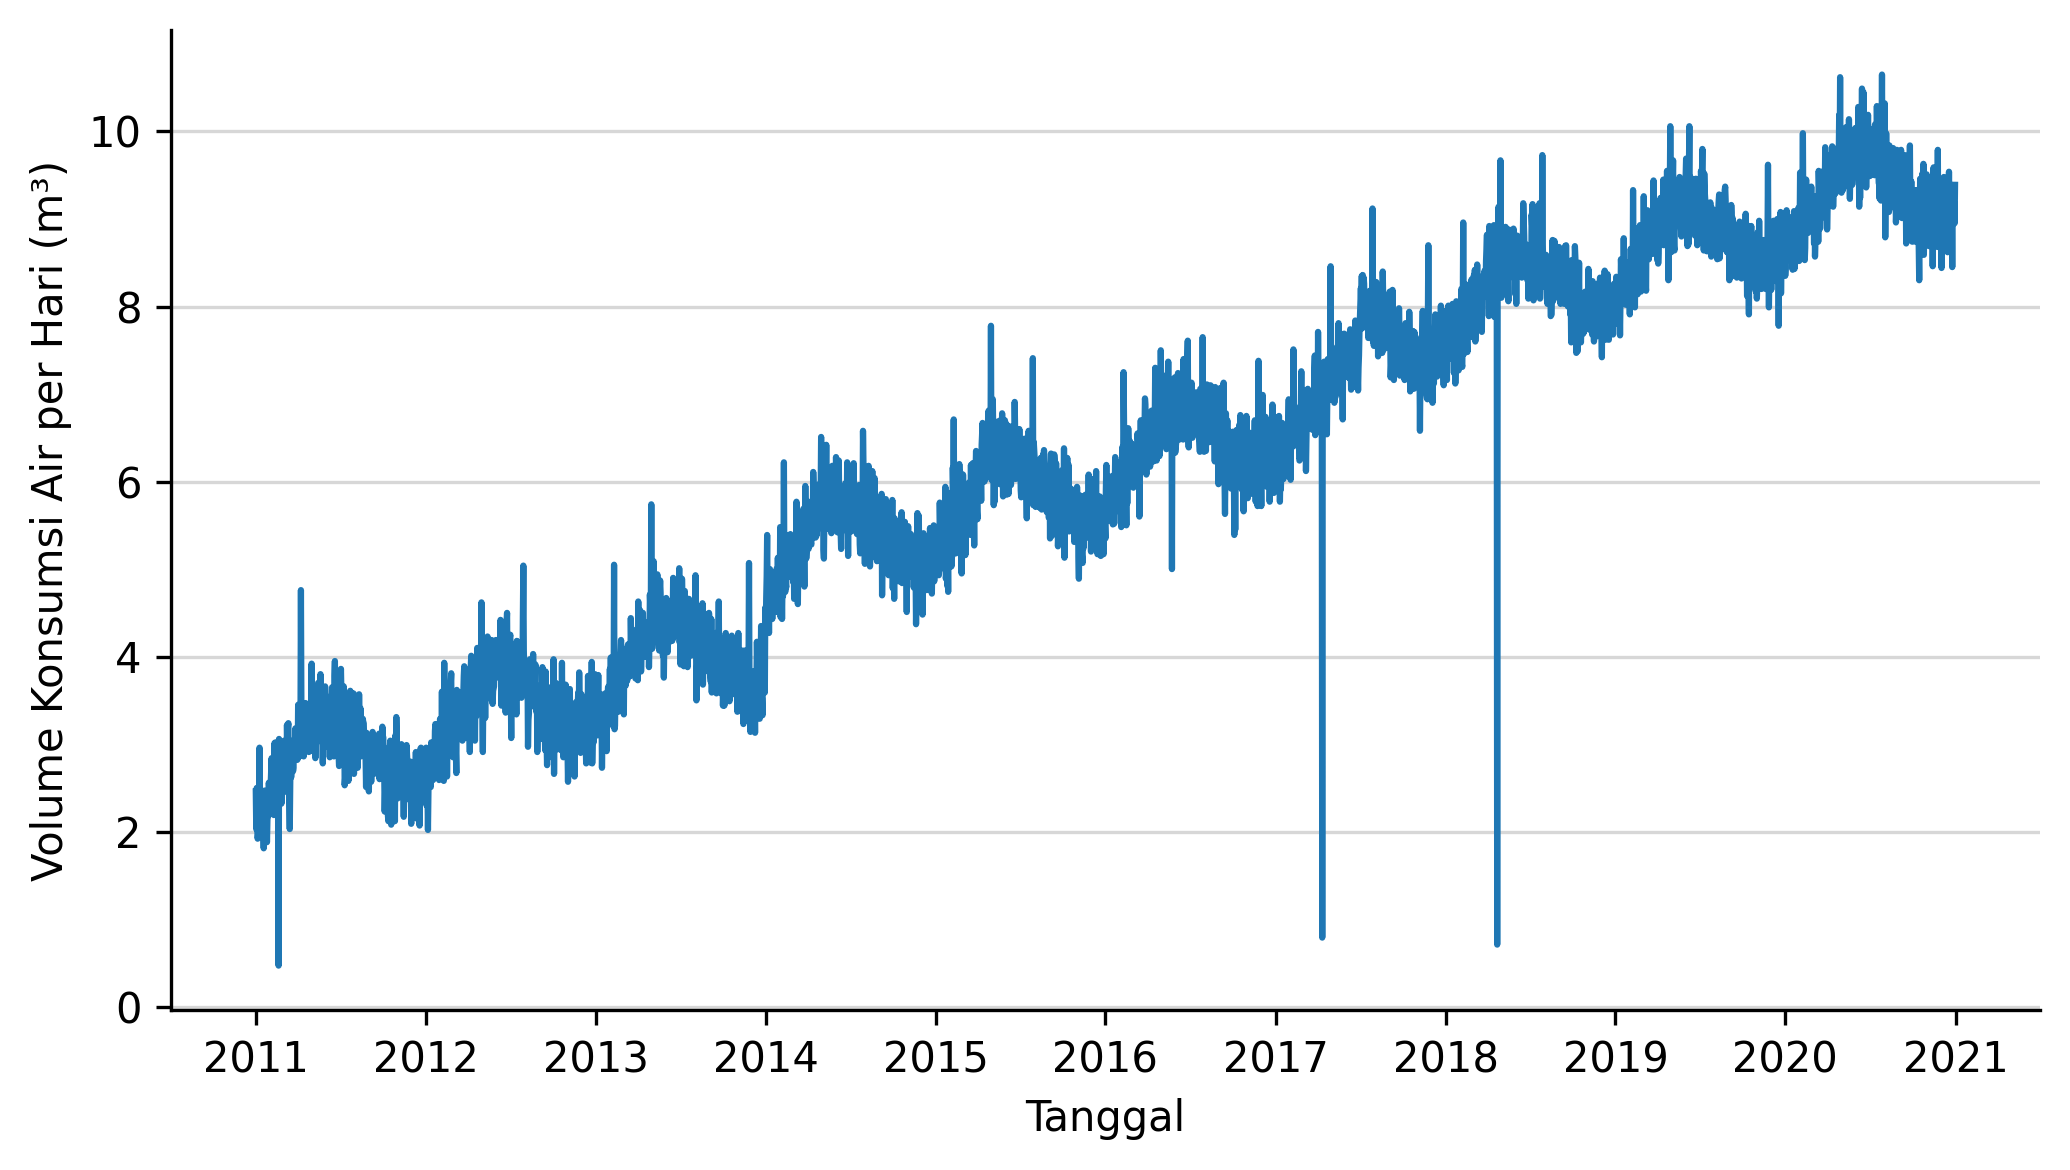

In [ ]:
plot_time_series(
    df["time"],
    df["water"],
    xlabel="Tanggal",
    ylabel="Volume Konsumsi Air per Hari (m³)",
    title="Dinamika Volume Konsumsi Air Harian (2011-2020)",
)

## Plot Dekomposisi

In [ ]:
from statsmodels.tsa.seasonal import seasonal_decompose

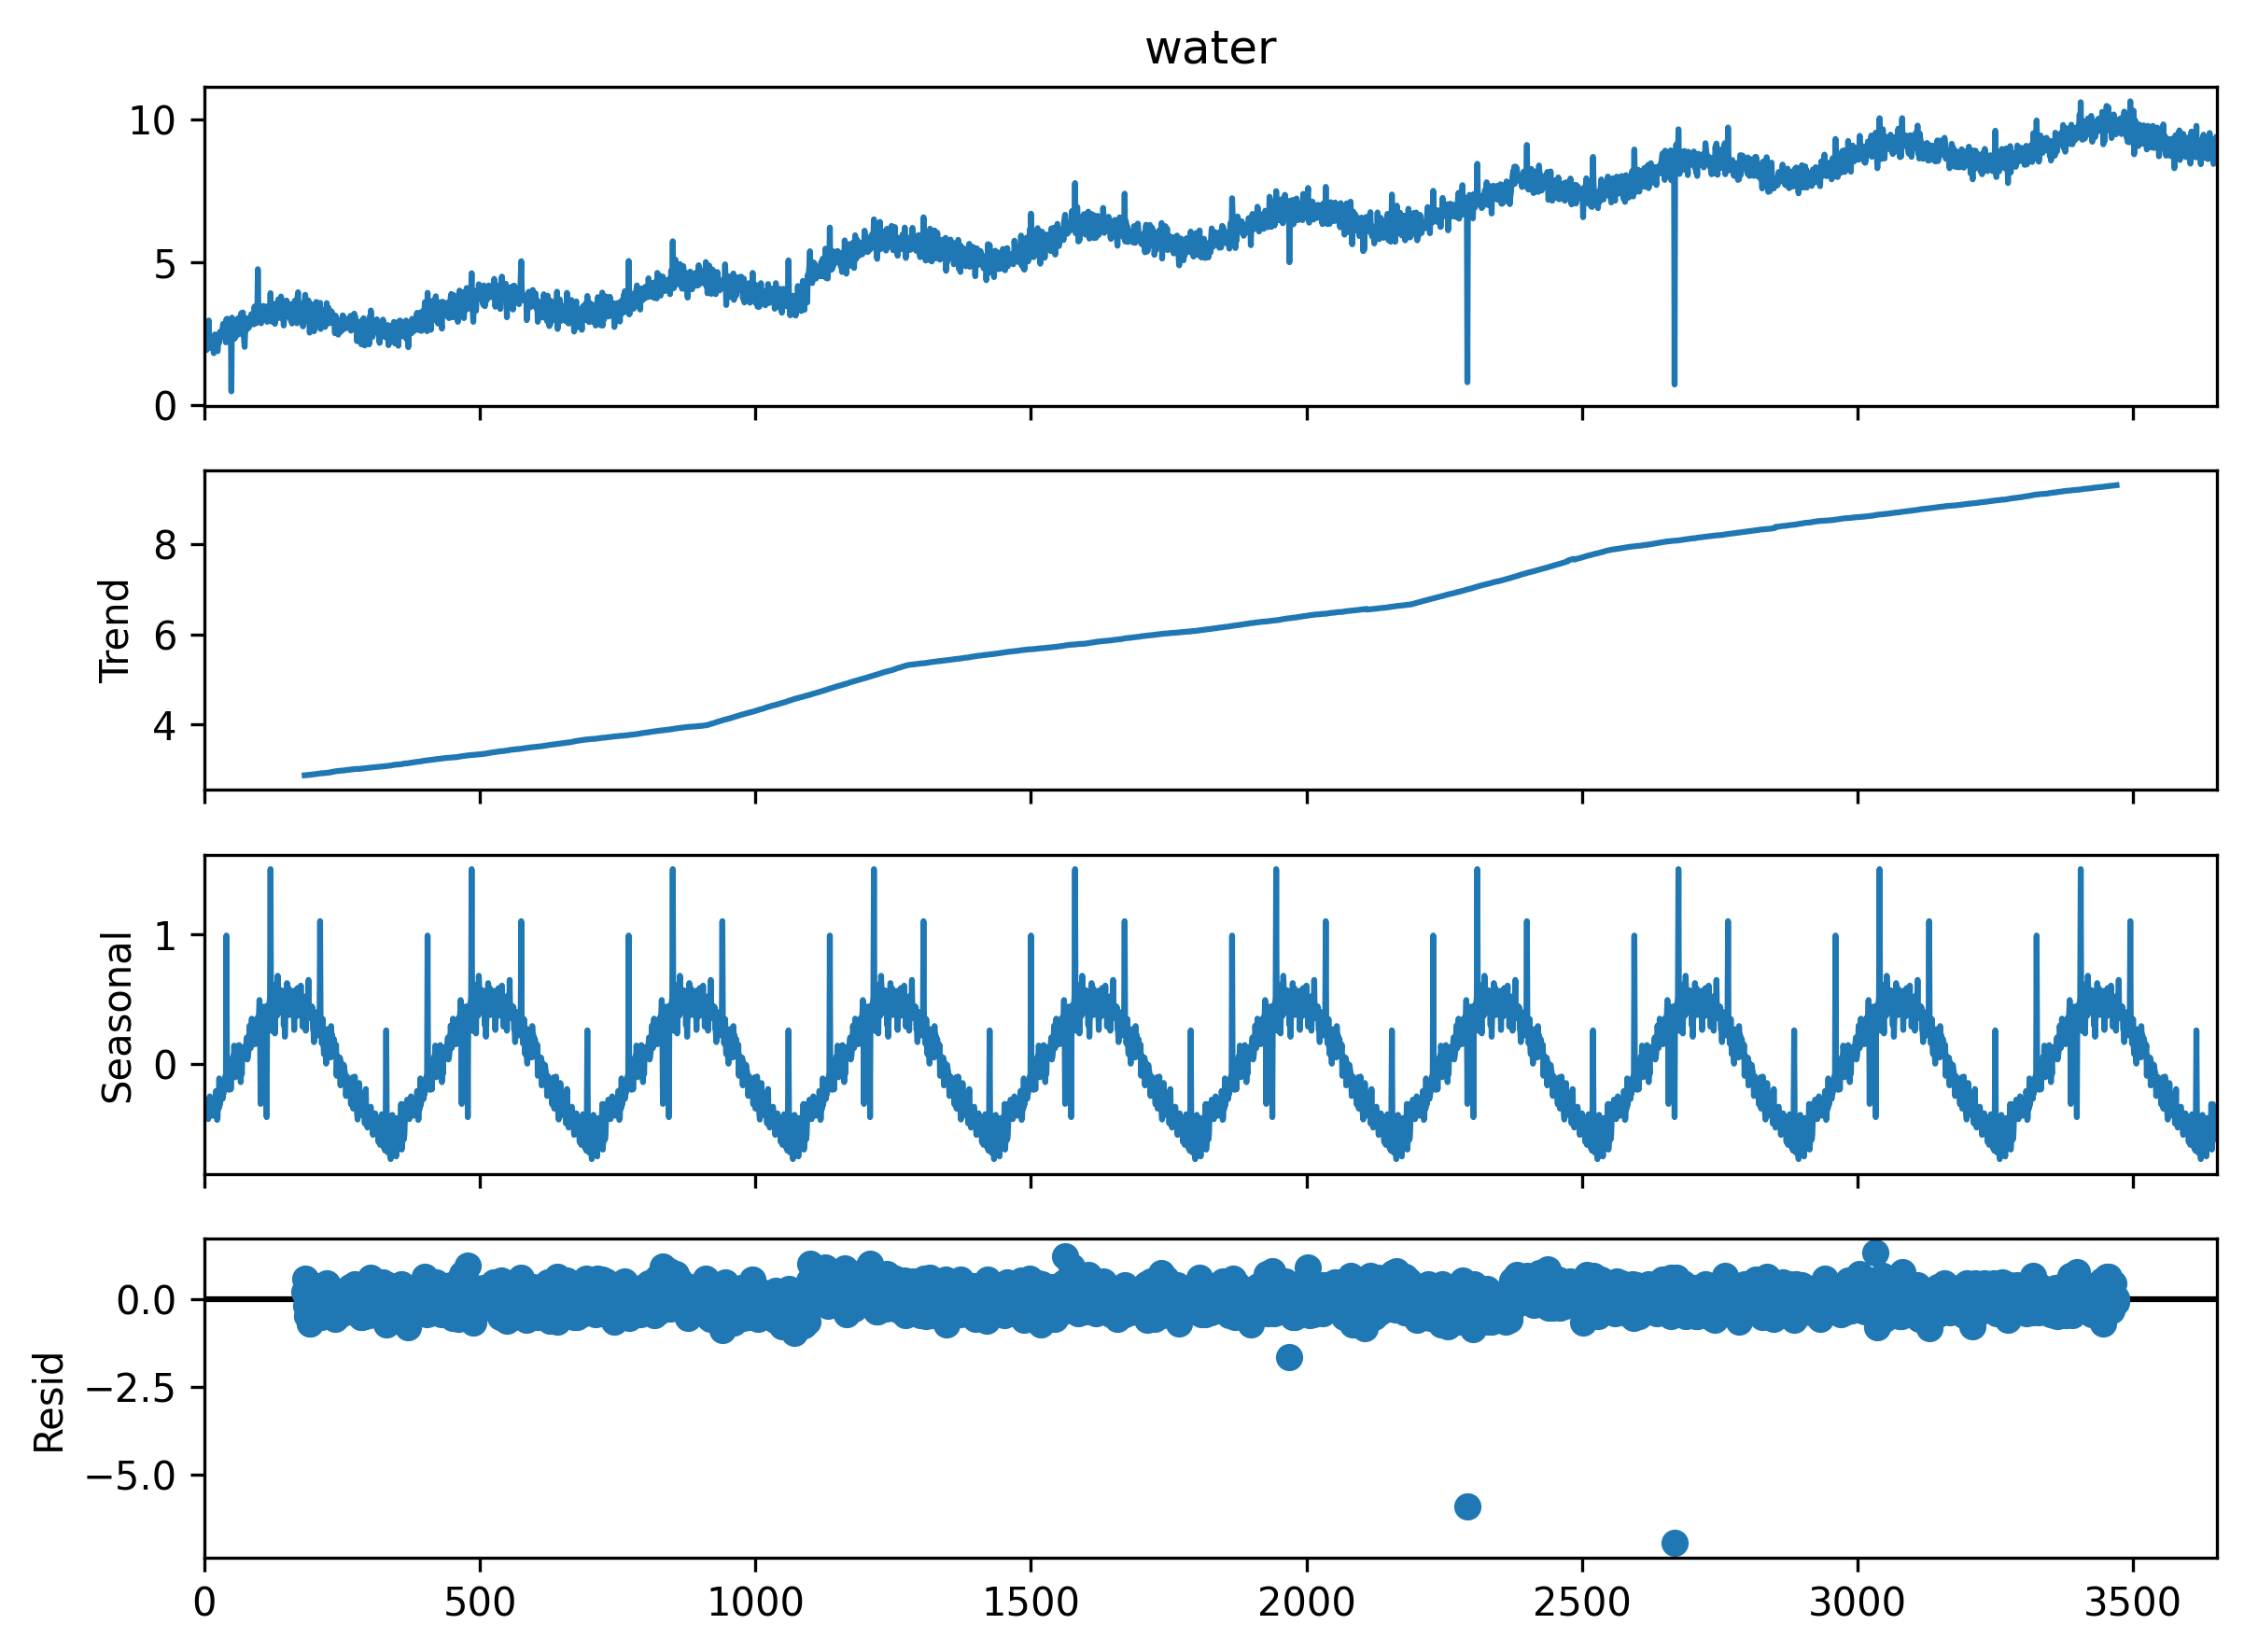

In [ ]:
# melihat pola musiman tahunan untuk data harian? gunakan period=365
# melihat pola musiman tahunan untuk data bulanan? gunakan period=12
# melihat pola musiman bulanan untuk data harian? gunakan period=30
# melihat pola musiman mingguan untuk data harian? gunakan period=7
# melihat pola musiman harian untuk data per jam? gunakan period=24
# dst

fig = seasonal_decompose(df['water'], model='additive', period=365).plot() # tahunan
fig.set_size_inches(8, 6)
fig.set_dpi(300)
plt.tight_layout()
plt.show()

# FEATURE ENGINEERING

Salah satu bentuk *feature engineering* pada data deret waktu adalah penambahan fitur turunan dari variabel asal. Pada analisis ini, dilakukan penambahan fitur sebagai berikut:
* **Lag features**. Fitur yang merepresentasikan nilai masa lalu dari deret waktu dan digunakan sebagai input untuk memprediksi nilai pada waktu sekarang atau masa depan. Fitur ini cocok untuk data yang memiliki keterkaitan (autokorelasi) antark waktu.
* **Rolling window features**. Fitur yang diperoleh dari ukuran statistik (misalnya rata-rata, median, atau simpangan baku) yang dihitung pada jendela waktu bergulir sepanjang deret waktu.
* **Expanding window features**. Fitur yang dihitung dengan menggunakan seluruh observasi dari awal periode pengamatan hingga titik waktu saat ini, misalnya rata-rata kumulatif.
* **Differencing**. Transformasi berupa selisih antar nilai berurutan untuk mengurangi tren linier atau pola musiman sehingga deret menjadi lebih stasioner.
* **Date–time features**. Fitur yang diekstraksi dari komponen waktu, seperti tahun, bulan, hari dalam bulan, atau hari dalam minggu, untuk menangkap pola yang terkait kalender.
* **Fourier features**. Fitur yang menggunakan kombinasi fungsi sinus dan cosinus dengan periode tertentu untuk merepresentasikan pola musiman yang berbentuk siklus halus.

In [ ]:
def add_features(
    df,
    col_time,
    col_value,
    lag_orders=[],
    roll_windows=[],
    diff_lags=[],
    fourier_periods=[],
):
    """
    df            : DataFrame dengan kolom waktu & nilai
    col_time      : nama kolom waktu (misal 'time')
    col_value     : nama kolom target (misal 'water')
    lag_orders    : list lag, misal [1, 7, 30]
    roll_windows  : list window rolling, misal [3, 7, 30]
    diff_lags     : list lag untuk differencing, misal [1, 7]
    fourier_periods : list period Fourier, misal [7, 30]
    """

    df_feat_ = df.copy()
    df_feat_["y"] = df_feat_[col_value]
    y = df_feat_["y"]

    # === Lag Features ===
    for k in lag_orders:
        df_feat_[f"lag{k}"] = y.shift(k)

    # basis rolling & expanding: pakai lag terkecil
    base_lag = min(lag_orders) if len(lag_orders) > 0 else 1
    base_series = y.shift(base_lag)

    # === Rolling Window Features ===
    for w in roll_windows:
        df_feat_[f"roll{w}_mean"] = base_series.rolling(w).mean()
        df_feat_[f"roll{w}_std"] = base_series.rolling(w).std()

    # === Expanding Window ===
    df_feat_["cum_mean"] = base_series.expanding().mean()
    df_feat_["cum_std"] = base_series.expanding().std()

    # === Differencing ===
    # diff{k}_t = y_{t-k} - y_{t-k-1}  (hanya pakai masa lalu)
    for k in diff_lags:
        df_feat_[f"diff{k}"] = y.shift(k) - y.shift(k + 1)

    # === Date-Time Features ===
    df_feat_["year"] = df_feat_[col_time].dt.year
    df_feat_["month"] = df_feat_[col_time].dt.month
    df_feat_["quarter"] = df_feat_[col_time].dt.quarter

    # === Fourier Features ===
    t = np.arange(len(df_feat_))
    for period in fourier_periods:
        df_feat_[f"fourier{period}_sin"] = np.sin(2 * np.pi * t / period)
        df_feat_[f"fourier{period}_cos"] = np.cos(2 * np.pi * t / period)

    # Bersihkan NaN awal (karena lag/rolling/diff) lalu buang kolom non-fitur
    df_feat_ = df_feat_.dropna().reset_index(drop=True)
    df_feat_ = df_feat_.drop(columns=[col_time, col_value, "year", "month"])

    return df_feat_

In [ ]:
lag_orders = [1, 7, 30] # 1 hari, 1 minggu, dan ±1 bulan ke belakang
roll_windows = [7] # rolling statistik berbasis 7 hari terakhir
diff_lags = [1, 7] # perubahan harian (t vs t-1) dan mingguan (t vs t-7)
fourier_periods = [7, 30] # komponen musiman mingguan (per 7 hari) dan bulanan (per 30 hari)

df_feat = add_features(
    df,
    col_time="time",
    col_value="water",
    lag_orders=lag_orders,
    roll_windows=roll_windows,
    diff_lags=diff_lags,
    fourier_periods=fourier_periods,
)
df_feat.head()

,y,lag1,lag7,lag30,roll7_mean,roll7_std,cum_mean,cum_std,diff1,diff7,quarter,fourier7_sin,fourier7_cos,fourier30_sin,fourier30_cos
0,2.415,2.440,2.18,2.46,2.254286,0.228536,2.221333,0.235953,-0.120,-0.23,1,0.974928,-0.222521,-1.133108e-15,1.000000
1,2.390,2.415,1.88,2.03,2.287857,0.233021,2.227581,0.234581,-0.025,-0.30,1,0.433884,-0.900969,2.079117e-01,0.978148
2,2.550,2.390,2.14,2.50,2.360714,0.148729,2.232656,0.232545,-0.025,0.26,1,-0.433884,-0.900969,4.067366e-01,0.913545
3,2.730,2.550,2.40,2.05,2.419286,0.126373,2.242273,0.235455,0.160,0.26,1,-0.974928,-0.222521,5.877853e-01,0.809017
4,2.840,2.730,2.18,1.92,2.466429,0.171482,2.256618,0.246487,0.180,-0.22,1,-0.781831,0.623490,7.431448e-01,0.669131


# SPLITTING

Berikut adalah aturan data splitting dalam kasus time series:
*   Urutan waktu wajib dipertahankan — tidak boleh shuffle.
*   Data train selalu lebih awal dari test — masa lalu → masa depan.
*   Tidak boleh ada data masa depan masuk ke train (no leakage).
*   Untuk data musiman, train dan test sebaiknya mencakup siklus musiman yang lengkap.
* Jika dataset pendek, gunakan Time Series Cross-Validation (rolling/expanding window). Bisa digunakan untuk tunning parameter
* Feature engineering harus dibuat hanya dari data train (lag, rolling, scaling).

In [ ]:
X = df_feat.drop(columns=['y'])
y = df_feat['y']

print('Variabel prediktor:', ', '.join(X.columns.values))
print('Variabel target: y')

Variabel prediktor: lag1, lag7, lag30, roll7_mean, roll7_std, cum_mean, cum_std, diff1, diff7, quarter, fourier7_sin, fourier7_cos, fourier30_sin, fourier30_cos
Variabel target: y


In [ ]:
train_ratio = 0.7 # jika ratio adalah 70:30, maka train_ratio = 0.7
split = int(train_ratio * len(X))

X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]

print("Ukuran data train:", X_train.shape[0], 'baris')
print("Ukuran data test :", X_test.shape[0], 'baris')

Ukuran data train: 2536 baris
Ukuran data test : 1087 baris


# PEMODELAN

In [ ]:
from sklearn.metrics import mean_absolute_percentage_error, mean_squared_error
from sklearn.model_selection import ParameterGrid

In [ ]:
def expanding_cv_score(model, X, y, n_folds=5):
    """
    Expanding window k-fold:
    - Data dibagi jadi blok waktu.
    - Fold 1: train = blok1,            val = blok2
      Fold 2: train = blok1+blok2,      val = blok3
      ...
    """
    n = len(X)
    if n_folds < 1:
        raise ValueError("n_folds harus >= 1")

    block_size = n // (n_folds + 1)
    if block_size == 0:
        raise ValueError("Data terlalu pendek untuk jumlah fold tersebut.")

    print(f"[Expanding CV] n={n}, n_folds={n_folds}, block_size≈{block_size}")

    scores = []

    for fold in range(1, n_folds + 1):
        train_end = block_size * fold
        val_start = train_end
        # fold terakhir: ambil sisa data sebagai validation
        val_end = block_size * (fold + 1) if fold < n_folds else n

        X_train, y_train = X.iloc[:train_end], y.iloc[:train_end]
        X_val,   y_val   = X.iloc[val_start:val_end], y.iloc[val_start:val_end]

        model.fit(X_train, y_train)
        preds = model.predict(X_val)
        fold_score = mean_absolute_percentage_error(y_val, preds)
        scores.append(fold_score)

        print(
            f"  Fold {fold}/{n_folds} | "
            f"train=[0:{train_end}) ({len(X_train)}), "
            f"val=[{val_start}:{val_end}) ({len(X_val)}) | "
            f"MAPE={fold_score:.4f}"
        )

    mean_score = float(np.mean(scores))
    print(f"  -> Mean MAPE (expanding, {n_folds} folds): {mean_score:.4f}")
    return mean_score


def expanding_grid_search(
    X,
    y,
    model_cls,
    param_grid,
    n_folds=5,
    verbose=True,
    **base_kwargs,
):
    """
    Grid search generik dengan expanding window k-fold.
    """
    best_score = np.inf
    best_params = None

    for params in ParameterGrid(param_grid):
        full_params = {**base_kwargs, **params}

        print("=== Evaluasi params (expanding):", full_params, "===")
        model = model_cls(**full_params)
        score = expanding_cv_score(model, X, y, n_folds=n_folds)

        if verbose:
            print(f"  Hasil: {full_params} → MAPE = {score:.4f}\n")

        if score < best_score:
            best_score = score
            best_params = full_params

    return best_params, best_score

In [ ]:
def sliding_cv_score(model, X, y, window_size, n_folds=5):
    """
    Sliding window k-fold:
    - Train window berukuran window_size yang bergeser.
    - Setelah train window, dipakai blok berikutnya sebagai validation.
    """
    n = len(X)
    if window_size >= n:
        raise ValueError("window_size harus lebih kecil dari jumlah data.")
    if n_folds < 1:
        raise ValueError("n_folds harus >= 1")

    usable = n - window_size
    block_size = max(1, usable // n_folds)

    print(
        f"[Sliding CV] n={n}, window_size={window_size}, "
        f"n_folds={n_folds}, block_size≈{block_size}"
    )

    scores = []
    fold = 0

    start = 0
    while fold < n_folds:
        train_start = start
        train_end   = train_start + window_size
        if train_end >= n:
            break  # tidak cukup data buat validation

        val_start = train_end
        val_end   = min(val_start + block_size, n)
        if val_start >= val_end:
            break

        X_train, y_train = X.iloc[train_start:train_end], y.iloc[train_start:train_end]
        X_val,   y_val   = X.iloc[val_start:val_end],   y.iloc[val_start:val_end]

        model.fit(X_train, y_train)
        preds = model.predict(X_val)
        fold_score = mean_absolute_percentage_error(y_val, preds)
        scores.append(fold_score)

        fold += 1
        print(
            f"  Fold {fold}/{n_folds} | "
            f"train=[{train_start}:{train_end}) ({len(X_train)}), "
            f"val=[{val_start}:{val_end}) ({len(X_val)}) | "
            f"MAPE={fold_score:.4f}"
        )

        # geser ke depan
        start += block_size
        if val_end == n:
            break

    if not scores:
        raise ValueError("Tidak ada fold yang terbentuk. Cek window_size / n_folds.")

    mean_score = float(np.mean(scores))
    print(f"  -> Mean MAPE (sliding, {len(scores)} folds): {mean_score:.4f}")
    return mean_score


def sliding_grid_search(
    X,
    y,
    model_cls,
    param_grid,
    window_size,
    n_folds=5,
    verbose=True,
    **base_kwargs,
):
    """
    Grid search generik dengan sliding window k-fold.
    """
    best_score = np.inf
    best_params = None

    for params in ParameterGrid(param_grid):
        full_params = {**base_kwargs, **params}

        print("=== Evaluasi params (sliding):", full_params, "===\n")
        model = model_cls(**full_params)
        score = sliding_cv_score(model, X, y, window_size=window_size, n_folds=n_folds)

        if verbose:
            print(f"  Hasil: {full_params} → MAPE = {score:.4f}\n")

        if score < best_score:
            best_score = score
            best_params = full_params

    return best_params, best_score


Expanding Window:

![](https://i.sstatic.net/C4mxn.png)

Sliding Window:

![](https://i.sstatic.net/QNlQl.png)

## Random Forest

In [ ]:
from sklearn.ensemble import RandomForestRegressor

### Training

#### Tanpa Tuning

In [ ]:
model_rfo = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1,
)
model_rfo.fit(X_train, y_train)

RandomForestRegressor(n_jobs=-1, random_state=42)

#### Tuning: Expanding Window

In [ ]:
param_grid = {
    "n_estimators": [100, 200],
    # "max_depth": [5, 10, None],
    # "max_features": ["sqrt", "log2"],
}

best_params, best_score = expanding_grid_search(
    X_train,
    y_train,
    RandomForestRegressor,
    param_grid,
    n_folds=5,
    random_state=42,
    n_jobs=-1,
)

print("Best Parameters:", best_params)
print("Best CV Score (MAPE):", best_score)

# Model terbaik
model_rfo = RandomForestRegressor(**best_params)
model_rfo.fit(X_train, y_train)

=== Evaluasi params (expanding): {'random_state': 42, 'n_jobs': -1, 'n_estimators': 100} ===
[Expanding CV] n=2536, n_folds=5, block_size≈422
  Fold 1/5 | train=[0:422) (422), val=[422:844) (422) | MAPE=0.1448
  Fold 2/5 | train=[0:844) (844), val=[844:1266) (422) | MAPE=0.1221
  Fold 3/5 | train=[0:1266) (1266), val=[1266:1688) (422) | MAPE=0.0820
  Fold 4/5 | train=[0:1688) (1688), val=[1688:2110) (422) | MAPE=0.0694
  Fold 5/5 | train=[0:2110) (2110), val=[2110:2536) (426) | MAPE=0.1240
  -> Mean MAPE (expanding, 5 folds): 0.1085
  Hasil: {'random_state': 42, 'n_jobs': -1, 'n_estimators': 100} → MAPE = 0.1085

=== Evaluasi params (expanding): {'random_state': 42, 'n_jobs': -1, 'n_estimators': 200} ===
[Expanding CV] n=2536, n_folds=5, block_size≈422
  Fold 1/5 | train=[0:422) (422), val=[422:844) (422) | MAPE=0.1461
  Fold 2/5 | train=[0:844) (844), val=[844:1266) (422) | MAPE=0.1213
  Fold 3/5 | train=[0:1266) (1266), val=[1266:1688) (422) | MAPE=0.0815
  Fold 4/5 | train=[0:1688) 

RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=42)

#### Tuning: Sliding Window

In [ ]:
param_grid = {
    "n_estimators": [100, 200],
    # "max_depth": [5, 10, None],
    # "max_features": ["sqrt", "log2"],
}

best_params, best_score = sliding_grid_search(
    X_train,
    y_train,
    RandomForestRegressor,
    param_grid,
    window_size=365,
    n_folds=5,
    random_state=42,
    n_jobs=-1,
)

print("Best Parameters:", best_params)
print("Best CV Score (MAPE):", best_score)

# Model terbaik
model_rfo = RandomForestRegressor(**best_params)
model_rfo.fit(X_train, y_train)

=== Evaluasi params (sliding): {'random_state': 42, 'n_jobs': -1, 'n_estimators': 100} ===

[Sliding CV] n=2536, window_size=365, n_folds=5, block_size≈434
  Fold 1/5 | train=[0:365) (365), val=[365:799) (434) | MAPE=0.1278
  Fold 2/5 | train=[434:799) (365), val=[799:1233) (434) | MAPE=0.1465
  Fold 3/5 | train=[868:1233) (365), val=[1233:1667) (434) | MAPE=0.0846
  Fold 4/5 | train=[1302:1667) (365), val=[1667:2101) (434) | MAPE=0.0705
  Fold 5/5 | train=[1736:2101) (365), val=[2101:2535) (434) | MAPE=0.1191
  -> Mean MAPE (sliding, 5 folds): 0.1097
  Hasil: {'random_state': 42, 'n_jobs': -1, 'n_estimators': 100} → MAPE = 0.1097

=== Evaluasi params (sliding): {'random_state': 42, 'n_jobs': -1, 'n_estimators': 200} ===

[Sliding CV] n=2536, window_size=365, n_folds=5, block_size≈434
  Fold 1/5 | train=[0:365) (365), val=[365:799) (434) | MAPE=0.1269
  Fold 2/5 | train=[434:799) (365), val=[799:1233) (434) | MAPE=0.1446
  Fold 3/5 | train=[868:1233) (365), val=[1233:1667) (434) | MAPE

RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=42)

### Feature Importance

In [ ]:
importances = model_rfo.feature_importances_
fi = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': importances
})
fi.sort_values(by='Importance', ascending=False)

,Feature,Importance
6,cum_std,0.426825
5,cum_mean,0.288355
3,roll7_mean,0.251514
0,lag1,0.005706
4,roll7_std,0.003946
1,lag7,0.003723
13,fourier30_cos,0.003188
7,diff1,0.003153
8,diff7,0.002909
2,lag30,0.002907


### Testing

In [ ]:
# Prediksi
y_pred_rfo = model_rfo.predict(X_test)

pred = X_test.copy()
pred['y'] = y_test
pred['y_pred'] = y_pred_rfo
pred["error"] = pred["y"] - pred["y_pred"]
pred.head()

,lag1,lag7,lag30,roll7_mean,roll7_std,cum_mean,cum_std,diff1,diff7,quarter,fourier7_sin,fourier7_cos,fourier30_sin,fourier30_cos,y,y_pred,error
2536,7.40,7.33,7.26,7.572857,0.310253,5.032714,1.592830,-0.30,-0.17,1,-4.338837e-01,-0.900969,-0.207912,-0.978148,7.82,7.377983,0.442017
2537,7.82,7.16,7.34,7.642857,0.301480,5.033800,1.593469,0.42,-0.17,1,-9.749279e-01,-0.222521,-0.406737,-0.913545,7.50,7.606742,-0.106742
2538,7.50,7.90,7.21,7.691429,0.229523,5.034761,1.593902,-0.32,0.74,1,-7.818315e-01,0.623490,-0.587785,-0.809017,7.89,7.756750,0.133250
2539,7.89,7.51,7.20,7.690000,0.228035,5.035872,1.594587,0.39,-0.39,1,4.511404e-14,1.000000,-0.743145,-0.669131,7.65,7.706100,-0.056100
2540,7.65,8.01,7.65,7.710000,0.215407,5.036889,1.595110,-0.24,0.50,1,7.818315e-01,0.623490,-0.866025,-0.500000,7.70,7.765900,-0.065900


In [ ]:
# Evaluasi
mse_rfo  = mean_squared_error(y_test, y_pred_rfo)
rmse_rfo = np.sqrt(mse_rfo)
mape_rfo = mean_absolute_percentage_error(y_test, y_pred_rfo)

print(f"MSE  : {mse_rfo:.4f}")
print(f"RMSE : {rmse_rfo:.4f}")
print(f"MAPE : {mape_rfo:.4%}")

MSE  : 1.5742
RMSE : 1.2547
MAPE : 12.9268%


## Gradient Boosting

In [ ]:
from sklearn.ensemble import GradientBoostingRegressor

### Training

#### Tanpa Tuning

In [ ]:
model_gbt = GradientBoostingRegressor(
    learning_rate=0.05,
    random_state=42,
)
model_gbt.fit(X_train, y_train)

GradientBoostingRegressor(learning_rate=0.05, random_state=42)

#### Tuning: Expanding Window

In [ ]:
param_grid = {
    "learning_rate": [0.01, 0.1],
}

best_params, best_score = expanding_grid_search(
    X_train,
    y_train,
    GradientBoostingRegressor,
    param_grid,
    n_folds=5,
    random_state=42,
)

print("Best Parameters:", best_params)
print("Best CV Score (MAPE):", best_score)

# Model terbaik
model_gbt = GradientBoostingRegressor(**best_params)
model_gbt.fit(X_train, y_train)

=== Evaluasi params (expanding): {'random_state': 42, 'learning_rate': 0.01} ===
[Expanding CV] n=2536, n_folds=5, block_size≈422
  Fold 1/5 | train=[0:422) (422), val=[422:844) (422) | MAPE=0.1580
  Fold 2/5 | train=[0:844) (844), val=[844:1266) (422) | MAPE=0.1460
  Fold 3/5 | train=[0:1266) (1266), val=[1266:1688) (422) | MAPE=0.1240
  Fold 4/5 | train=[0:1688) (1688), val=[1688:2110) (422) | MAPE=0.1291
  Fold 5/5 | train=[0:2110) (2110), val=[2110:2536) (426) | MAPE=0.1874
  -> Mean MAPE (expanding, 5 folds): 0.1489
  Hasil: {'random_state': 42, 'learning_rate': 0.01} → MAPE = 0.1489

=== Evaluasi params (expanding): {'random_state': 42, 'learning_rate': 0.1} ===
[Expanding CV] n=2536, n_folds=5, block_size≈422
  Fold 1/5 | train=[0:422) (422), val=[422:844) (422) | MAPE=0.1523
  Fold 2/5 | train=[0:844) (844), val=[844:1266) (422) | MAPE=0.1101
  Fold 3/5 | train=[0:1266) (1266), val=[1266:1688) (422) | MAPE=0.0752
  Fold 4/5 | train=[0:1688) (1688), val=[1688:2110) (422) | MAPE=

GradientBoostingRegressor(random_state=42)

#### Tuning: Sliding Window

In [ ]:
param_grid = {
    "learning_rate": [0.01, 0.1],
}

best_params, best_score = sliding_grid_search(
    X_train,
    y_train,
    GradientBoostingRegressor,
    param_grid,
    window_size=365,
    n_folds=5,
    random_state=42,
)

print("Best Parameters:", best_params)
print("Best CV Score (MAPE):", best_score)

# Model terbaik
model_gbt = GradientBoostingRegressor(**best_params)
model_gbt.fit(X_train, y_train)

=== Evaluasi params (sliding): {'random_state': 42, 'learning_rate': 0.01} ===

[Sliding CV] n=2536, window_size=365, n_folds=5, block_size≈434
  Fold 1/5 | train=[0:365) (365), val=[365:799) (434) | MAPE=0.1458
  Fold 2/5 | train=[434:799) (365), val=[799:1233) (434) | MAPE=0.1648
  Fold 3/5 | train=[868:1233) (365), val=[1233:1667) (434) | MAPE=0.0862
  Fold 4/5 | train=[1302:1667) (365), val=[1667:2101) (434) | MAPE=0.0774
  Fold 5/5 | train=[1736:2101) (365), val=[2101:2535) (434) | MAPE=0.1261
  -> Mean MAPE (sliding, 5 folds): 0.1201
  Hasil: {'random_state': 42, 'learning_rate': 0.01} → MAPE = 0.1201

=== Evaluasi params (sliding): {'random_state': 42, 'learning_rate': 0.1} ===

[Sliding CV] n=2536, window_size=365, n_folds=5, block_size≈434
  Fold 1/5 | train=[0:365) (365), val=[365:799) (434) | MAPE=0.1449
  Fold 2/5 | train=[434:799) (365), val=[799:1233) (434) | MAPE=0.1607
  Fold 3/5 | train=[868:1233) (365), val=[1233:1667) (434) | MAPE=0.0846
  Fold 4/5 | train=[1302:1667

GradientBoostingRegressor(learning_rate=0.01, random_state=42)

### Feature Importance

In [ ]:
importances = model_gbt.feature_importances_
fi = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': importances
})
fi.sort_values(by='Importance', ascending=False)

,Feature,Importance
5,cum_mean,0.396534
3,roll7_mean,0.331273
6,cum_std,0.253213
0,lag1,0.014081
1,lag7,0.004899
2,lag30,0.000000
4,roll7_std,0.000000
7,diff1,0.000000
8,diff7,0.000000
9,quarter,0.000000


### Testing

In [ ]:
# Prediksi
y_pred_gbt = model_gbt.predict(X_test)

pred = X_test.copy()
pred['y'] = y_test
pred['y_pred'] = y_pred_gbt
pred["error"] = pred["y"] - pred["y_pred"]
pred.head()

,lag1,lag7,lag30,roll7_mean,roll7_std,cum_mean,cum_std,diff1,diff7,quarter,fourier7_sin,fourier7_cos,fourier30_sin,fourier30_cos,y,y_pred,error
2536,7.40,7.33,7.26,7.572857,0.310253,5.032714,1.592830,-0.30,-0.17,1,-4.338837e-01,-0.900969,-0.207912,-0.978148,7.82,6.623818,1.196182
2537,7.82,7.16,7.34,7.642857,0.301480,5.033800,1.593469,0.42,-0.17,1,-9.749279e-01,-0.222521,-0.406737,-0.913545,7.50,6.691688,0.808312
2538,7.50,7.90,7.21,7.691429,0.229523,5.034761,1.593902,-0.32,0.74,1,-7.818315e-01,0.623490,-0.587785,-0.809017,7.89,6.691688,1.198312
2539,7.89,7.51,7.20,7.690000,0.228035,5.035872,1.594587,0.39,-0.39,1,4.511404e-14,1.000000,-0.743145,-0.669131,7.65,6.691688,0.958312
2540,7.65,8.01,7.65,7.710000,0.215407,5.036889,1.595110,-0.24,0.50,1,7.818315e-01,0.623490,-0.866025,-0.500000,7.70,6.691688,1.008312


In [ ]:
# Evaluasi
mse_gbt  = mean_squared_error(y_test, y_pred_gbt)
rmse_gbt = np.sqrt(mse_gbt)
mape_gbt = mean_absolute_percentage_error(y_test, y_pred_gbt)

print(f"MSE  : {mse_gbt:.4f}")
print(f"RMSE : {rmse_gbt:.4f}")
print(f"MAPE : {mape_gbt:.4%}")

MSE  : 4.7208
RMSE : 2.1727
MAPE : 24.0931%


## Support Vector Regression (SVR)

In [ ]:
from sklearn.svm import SVR

### Training

#### Tanpa Tuning

In [ ]:
model_svr = SVR(kernel='linear', epsilon=0.1)
model_svr.fit(X_train, y_train)

SVR(kernel='linear')

#### Tuning: Expanding Window

In [ ]:
param_grid = {
    'kernel': ['linear', 'poly', 'rbf', 'sigmoid'],
    'epsilon': [0.01, 0.1, 1],
}

best_params, best_score = expanding_grid_search(
    X_train,
    y_train,
    SVR,
    param_grid,
    n_folds=5,
)

print("Best Parameters:", best_params)
print("Best CV Score (MAPE):", best_score)

# Model terbaik
model_svr = SVR(**best_params)
model_svr.fit(X_train, y_train)

=== Evaluasi params (expanding): {'epsilon': 0.01, 'kernel': 'linear'} ===
[Expanding CV] n=2536, n_folds=5, block_size≈422
  Fold 1/5 | train=[0:422) (422), val=[422:844) (422) | MAPE=0.0740
  Fold 2/5 | train=[0:844) (844), val=[844:1266) (422) | MAPE=0.0492
  Fold 3/5 | train=[0:1266) (1266), val=[1266:1688) (422) | MAPE=0.0439
  Fold 4/5 | train=[0:1688) (1688), val=[1688:2110) (422) | MAPE=0.0379
  Fold 5/5 | train=[0:2110) (2110), val=[2110:2536) (426) | MAPE=0.0515
  -> Mean MAPE (expanding, 5 folds): 0.0513
  Hasil: {'epsilon': 0.01, 'kernel': 'linear'} → MAPE = 0.0513

=== Evaluasi params (expanding): {'epsilon': 0.01, 'kernel': 'poly'} ===
[Expanding CV] n=2536, n_folds=5, block_size≈422
  Fold 1/5 | train=[0:422) (422), val=[422:844) (422) | MAPE=0.0688
  Fold 2/5 | train=[0:844) (844), val=[844:1266) (422) | MAPE=0.1021
  Fold 3/5 | train=[0:1266) (1266), val=[1266:1688) (422) | MAPE=0.0723
  Fold 4/5 | train=[0:1688) (1688), val=[1688:2110) (422) | MAPE=0.0703
  Fold 5/5 |

SVR(kernel='linear')

#### Tuning: Sliding Window

In [ ]:
param_grid = {
    'kernel': ['linear', 'poly', 'rbf', 'sigmoid'],
    'epsilon': [0.01, 0.1, 1],
}

best_params, best_score = sliding_grid_search(
    X_train,
    y_train,
    SVR,
    param_grid,
    window_size=365,
    n_folds=5,
)

print("Best Parameters:", best_params)
print("Best CV Score (MAPE):", best_score)

# Model terbaik
model_svr = SVR(**best_params)
model_svr.fit(X_train, y_train)

=== Evaluasi params (sliding): {'epsilon': 0.01, 'kernel': 'linear'} ===

[Sliding CV] n=2536, window_size=365, n_folds=5, block_size≈434
  Fold 1/5 | train=[0:365) (365), val=[365:799) (434) | MAPE=0.0748
  Fold 2/5 | train=[434:799) (365), val=[799:1233) (434) | MAPE=0.0681
  Fold 3/5 | train=[868:1233) (365), val=[1233:1667) (434) | MAPE=0.0482
  Fold 4/5 | train=[1302:1667) (365), val=[1667:2101) (434) | MAPE=0.0407
  Fold 5/5 | train=[1736:2101) (365), val=[2101:2535) (434) | MAPE=0.0518
  -> Mean MAPE (sliding, 5 folds): 0.0567
  Hasil: {'epsilon': 0.01, 'kernel': 'linear'} → MAPE = 0.0567

=== Evaluasi params (sliding): {'epsilon': 0.01, 'kernel': 'poly'} ===

[Sliding CV] n=2536, window_size=365, n_folds=5, block_size≈434
  Fold 1/5 | train=[0:365) (365), val=[365:799) (434) | MAPE=0.0716
  Fold 2/5 | train=[434:799) (365), val=[799:1233) (434) | MAPE=0.0700
  Fold 3/5 | train=[868:1233) (365), val=[1233:1667) (434) | MAPE=0.0552
  Fold 4/5 | train=[1302:1667) (365), val=[1667:

SVR(epsilon=0.01, kernel='linear')

### Testing

In [ ]:
# Prediksi
y_pred_svr = model_svr.predict(X_test)

pred = X_test.copy()
pred['y'] = y_test
pred['y_pred'] = y_pred_svr
pred["error"] = pred["y"] - pred["y_pred"]
pred.head()

,lag1,lag7,lag30,roll7_mean,roll7_std,cum_mean,cum_std,diff1,diff7,quarter,fourier7_sin,fourier7_cos,fourier30_sin,fourier30_cos,y,y_pred,error
2536,7.40,7.33,7.26,7.572857,0.310253,5.032714,1.592830,-0.30,-0.17,1,-4.338837e-01,-0.900969,-0.207912,-0.978148,7.82,7.499373,0.320627
2537,7.82,7.16,7.34,7.642857,0.301480,5.033800,1.593469,0.42,-0.17,1,-9.749279e-01,-0.222521,-0.406737,-0.913545,7.50,7.630142,-0.130142
2538,7.50,7.90,7.21,7.691429,0.229523,5.034761,1.593902,-0.32,0.74,1,-7.818315e-01,0.623490,-0.587785,-0.809017,7.89,7.714305,0.175695
2539,7.89,7.51,7.20,7.690000,0.228035,5.035872,1.594587,0.39,-0.39,1,4.511404e-14,1.000000,-0.743145,-0.669131,7.65,7.868947,-0.218947
2540,7.65,8.01,7.65,7.710000,0.215407,5.036889,1.595110,-0.24,0.50,1,7.818315e-01,0.623490,-0.866025,-0.500000,7.70,7.832715,-0.132715


In [ ]:
# Evaluasi
mse_svr  = mean_squared_error(y_test, y_pred_svr)
rmse_svr = np.sqrt(mse_svr)
mape_svr = mean_absolute_percentage_error(y_test, y_pred_svr)

print(f"MSE  : {mse_svr:.4f}")
print(f"RMSE : {rmse_svr:.4f}")
print(f"MAPE : {mape_svr:.4%}")

MSE  : 0.1438
RMSE : 0.3792
MAPE : 3.6123%


# PERBANDINGAN MODEL

In [ ]:
comparison = pd.DataFrame({
    'Model': ['Random Forest', 'Gradient Boosting', 'SVR'],
    'MSE': [mse_rfo, mse_gbt, mse_svr],
    'RMSE': [rmse_rfo, rmse_gbt, rmse_svr],
    'MAPE': [mape_rfo, mape_gbt, mape_svr],
})
comparison['MAPE (%)'] = comparison['MAPE'] * 100
comparison = comparison.sort_values(by='MAPE (%)')
comparison

,Model,MSE,RMSE,MAPE,MAPE (%)
2,SVR,0.143775,0.379176,0.036123,3.612283
0,Random Forest,1.574175,1.254661,0.129268,12.926789
1,Gradient Boosting,4.720800,2.172740,0.240931,24.093092


# PERAMALAN

In [ ]:
best_model = model_svr

In [ ]:
def forecast_next(
    model,
    df_hist,
    steps,
    title,
    xlabel,
    ylabel,
    col_time,
    col_value,
    freq,
    figsize=(7,4),
    dpi=300,
):
    df_hist = df_hist.copy()
    df_hist[col_time] = pd.to_datetime(df_hist[col_time])
    df_hist = df_hist.sort_values(col_time)

    # list waktu & nilai (akan ditambah dengan prediksi)
    times = list(df_hist[col_time])
    values = list(df_hist[col_value])

    preds = []
    offset = pd.tseries.frequencies.to_offset(freq)

    for i in range(steps):
        # bangun df sementara dari seluruh history (data asli + prediksi sebelumnya)
        df_tmp = pd.DataFrame({col_time: times, col_value: values})

        # bangun fitur kausal
        df_feat_tmp = add_features(
            df_tmp, col_time, col_value,
            lag_orders=lag_orders,
            roll_windows=roll_windows,
            diff_lags=diff_lags,
            fourier_periods=fourier_periods,
        )
        X_tmp = df_feat_tmp.drop(columns=["y"])

        # pakai baris fitur terakhir untuk prediksi next-step
        X_last = X_tmp.iloc[[-1]]
        y_next = model.predict(X_last)[0]

        # waktu berikutnya = waktu terakhir + 1 hari (kalau freq='D')
        next_time = times[-1] + offset

        # simpan ke history dan ke list prediksi
        times.append(next_time)
        values.append(y_next)
        preds.append((next_time, y_next))

        print(f'\rBerhasil memprediksi hingga {next_time} ({i+1}/{steps} periode ke depan): {y_next}', end='', flush=True)

    # DataFrame hasil prediksi
    df_future = pd.DataFrame(preds, columns=[col_time, col_value])

    # Plot historis + prediksi
    print(f'\n{title}')
    plt.figure(figsize=figsize, dpi=dpi)
    plt.plot(df_hist[col_time], df_hist[col_value], label="Histori")
    plt.plot(df_future[col_time], df_future[col_value], "o-", label="Ramalan", linewidth=2)

    ax = plt.gca()
    ax.set_axisbelow(True)
    ax.grid(True, axis="y", linestyle="-", alpha=0.5)

    plt.xlabel(xlabel)
    plt.ylabel(ylabel)

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    plt.legend()
    plt.tight_layout()
    plt.show()

    return df_future

Opsi `freq`:
* `D` = harian (calendar day)
* `B` = hari kerja (business day, tanpa Sabtu–Minggu)
* `W` = mingguan (akhir minggu, default Minggu)
* `W-MON` / `W-FRI` = mingguan, akhir minggu di hari tertentu (Senin/Jumat, dst)
* `H` = per jam (hourly)
* `T` / `min` = per menit
* `S` = per detik
* `M` = bulanan, akhir bulan
* `MS` = bulanan, awal bulan
* `Q` = triwulanan, akhir kuartal
* `QS` = triwulanan, awal kuartal
* `A` / `Y` = tahunan, akhir tahun
* `AS` / `YS` = tahunan, awal tahun

Berhasil memprediksi hingga 2022-12-31 00:00:00 (730/730 periode ke depan): 10.718187304250707
Histori dan Ramalan Volume Konsumsi Air Harian


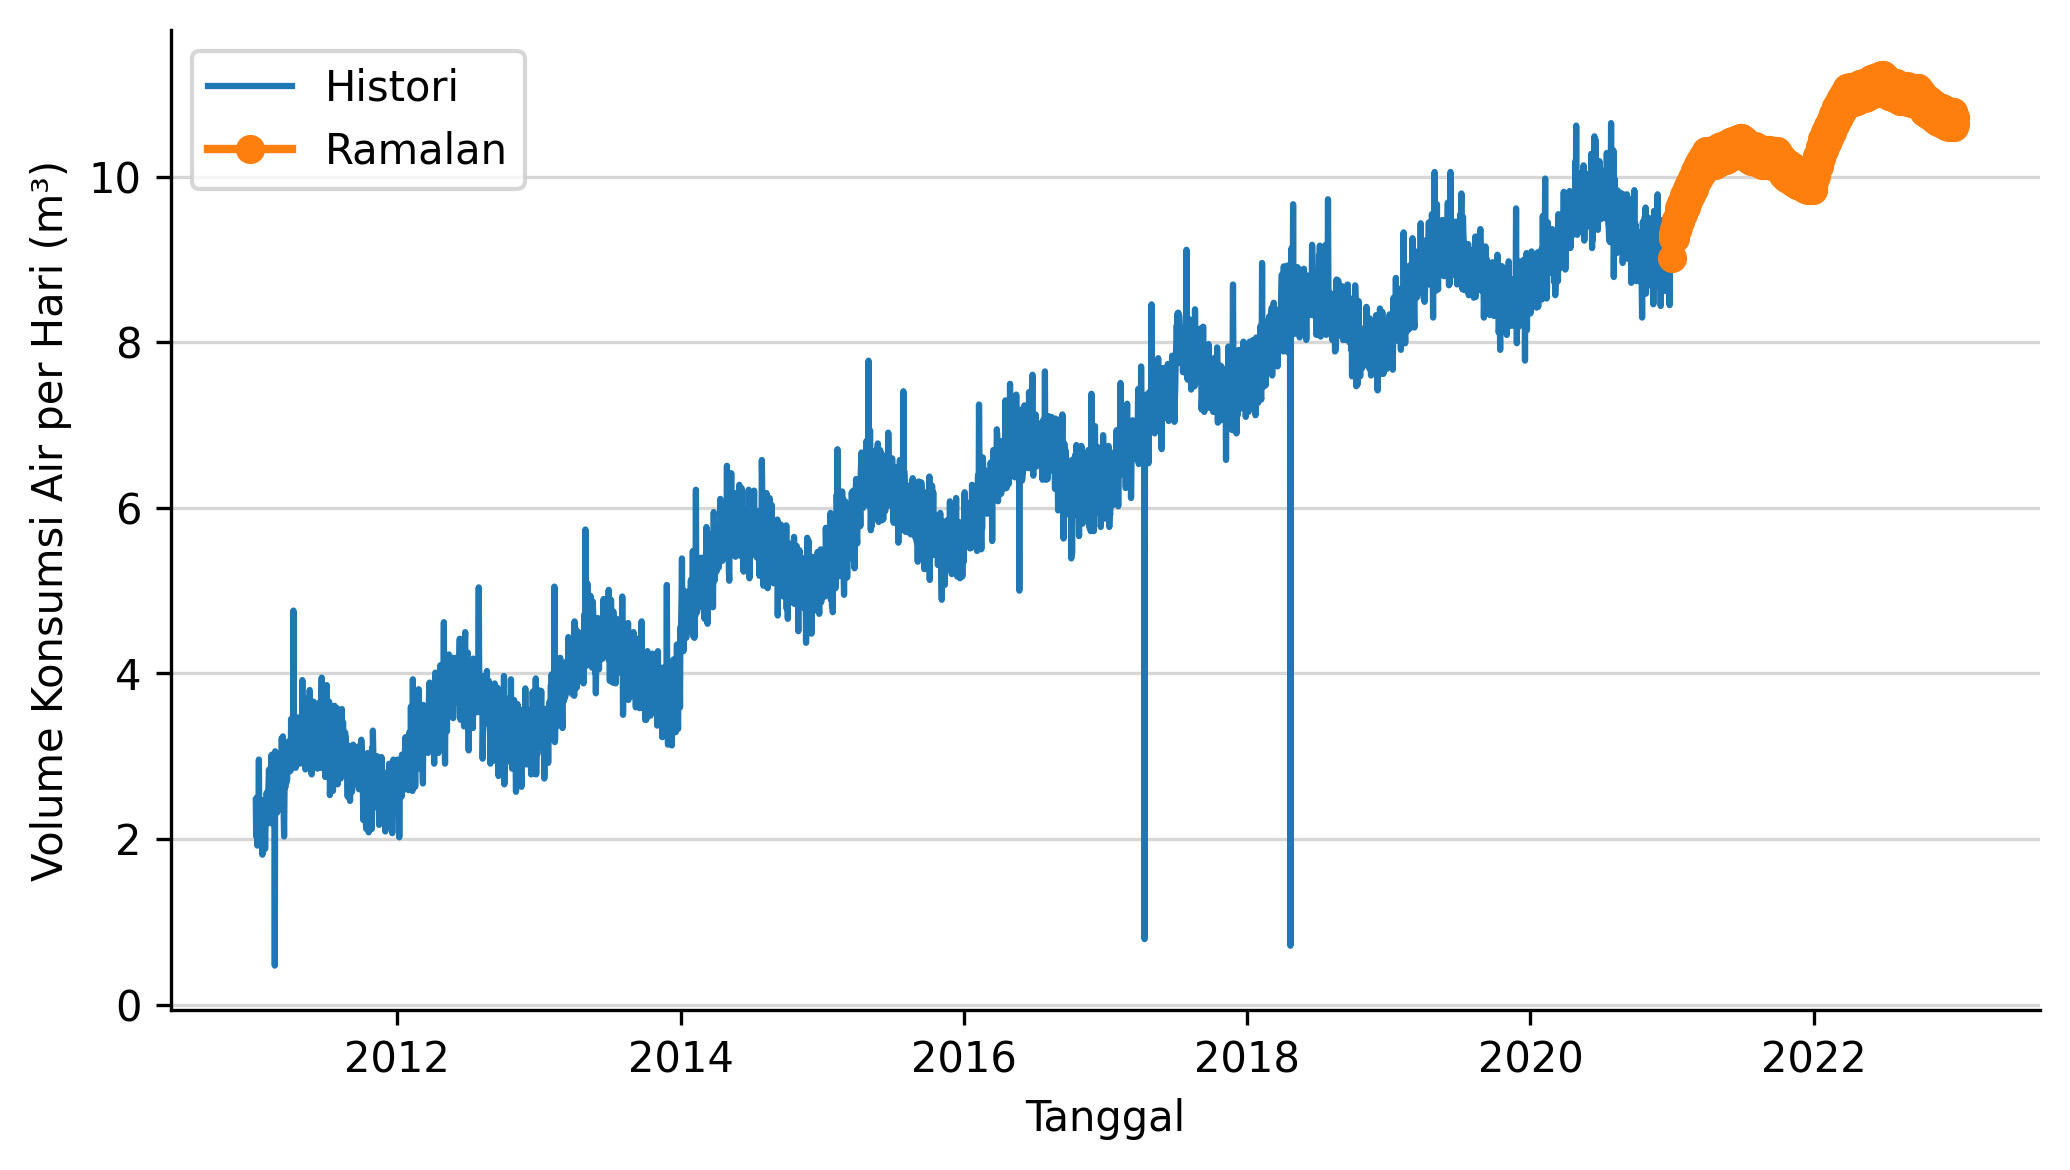

In [ ]:
df_future = forecast_next(
    model=best_model,
    steps=365*2, # sekitar 2 tahun ke depan
    freq="D",
    df_hist=df,
    col_time="time",
    col_value="water",
    xlabel="Tanggal",
    ylabel="Volume Konsumsi Air per Hari (m³)",
    title="Histori dan Ramalan Volume Konsumsi Air Harian",
)

In [ ]:
# 10 hari ke depan
df_future.head(10)

,time,water
0,2021-01-01,9.015809
1,2021-01-02,9.267707
2,2021-01-03,9.312638
3,2021-01-04,9.376491
4,2021-01-05,9.316233
5,2021-01-06,9.274955
6,2021-01-07,9.266675
7,2021-01-08,9.317117
8,2021-01-09,9.398747
9,2021-01-10,9.484789


In [ ]:
# 10 hari terakhir ramalan
df_future.tail(10)

,time,water
720,2022-12-22,10.607286
721,2022-12-23,10.647913
722,2022-12-24,10.728030
723,2022-12-25,10.786863
724,2022-12-26,10.779521
725,2022-12-27,10.710775
726,2022-12-28,10.631476
727,2022-12-29,10.600273
728,2022-12-30,10.639459
729,2022-12-31,10.718187
